In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys
%matplotlib inline

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "scripts" / "data_cleaning.py").is_file()),
    None,
)

sys.path.insert(0, str(PROJECT_ROOT))
from scripts.data_cleaning import DATA_ROOT

df = pd.read_csv(DATA_ROOT / "AI_Usage_and_Impact_on_Students_and_Professionals_cleaned.csv")

df.head(5)

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30.0,Male,United Kingdom,Professional,Master's,Business Analyst,5421.0,chatgpt,Office Work,2.0,Data analysis using AI-powered analytics tools...,0.0,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30.0,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903.0,chatgpt,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0.0,9.9,3.0,9.0,11.4,8.4,Yes
2,U0152,17.0,Male,Canada,Student,Bachelor's,Computer Science Student,402.0,chat gpt,Coding,1.0,"Debugging code with AI assistance, generating ...",20.0,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35.0,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367.0,meta ai,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20.0,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19.0,Female,Canada,Student,Undergraduate,Biology Student,438.0,perplexity ai,Coding,4.1,Using AI to generate study summaries for exam ...,0.0,4.7,4.0,7.0,9.2,6.2,Yes


In [2]:
df.columns

Index(['User_ID', 'Age', 'Gender', 'Country', 'User_Type', 'Education_Level',
       'Profession', 'Monthly_Income', 'AI_Tool', 'AI_Purpose',
       'AI_Usage_Hours_Per_Day', 'Tasks_Performed', 'Monthly_AI_Cost',
       'Productivity_Score', 'Accuracy_Rating', 'Satisfaction_Score',
       'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day',
       'Would_Recommend'],
      dtype='str')

In [3]:
numeric_cols = df.select_dtypes(include=["number"])
categories_cols = df.drop(columns=numeric_cols.columns).drop(columns="Tasks_Performed")

tasks_performed = df["Tasks_Performed"]

In [4]:
numeric_cols

,Age,Monthly_Income,AI_Usage_Hours_Per_Day,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day
0,30.0,5421.0,2.0,0.0,5.3,4.0,7.0,3.9,7.3
1,30.0,8903.0,5.7,0.0,9.9,3.0,9.0,11.4,8.4
2,17.0,402.0,1.0,20.0,3.2,2.0,4.0,5.2,6.7
3,35.0,1367.0,1.7,20.0,5.6,4.0,5.0,6.4,9.6
4,19.0,438.0,4.1,0.0,4.7,4.0,7.0,9.2,6.2
...,...,...,...,...,...,...,...,...,...
283,27.0,8255.0,1.8,0.0,1.8,3.0,4.0,5.0,12.2
284,43.0,523.5,1.2,0.0,4.7,3.0,6.0,1.0,10.9
285,48.0,544.0,5.5,0.0,7.8,4.0,7.0,11.5,8.4
286,31.0,448.0,0.7,0.0,4.3,3.0,4.0,1.7,9.5


In [5]:
categories_cols

,User_ID,Gender,Country,User_Type,Education_Level,Profession,AI_Tool,AI_Purpose,Would_Recommend
0,U0269,Male,United Kingdom,Professional,Master's,Business Analyst,chatgpt,Office Work,Yes
1,U0217,Male,United States,Professional,Bachelor's,Customer Support Specialist,chatgpt,Customer Support,Yes
2,U0152,Male,Canada,Student,Bachelor's,Computer Science Student,chat gpt,Coding,No
3,U0264,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,meta ai,Coding,Maybe
4,U0263,Female,Canada,Student,Undergraduate,Biology Student,perplexity ai,Coding,Yes
...,...,...,...,...,...,...,...,...,...
283,U0066,Female,United States,Professional,Bachelor's,English Literature Student,microsoft copilot,Coding,No
284,U0094,Male,Nigeria,Professional,Diploma,Multimedia Content Producer,chatgpt,Content Creation,No
285,U0136,Male,Brazil,Professional,Diploma,Desenvolvedor de Sistemas (Systems Developer),google gemini,Coding,Yes
286,U0002,Female,Pakistan,Professional,Diploma,Junior Software Developer,chatgpt,Coding,No


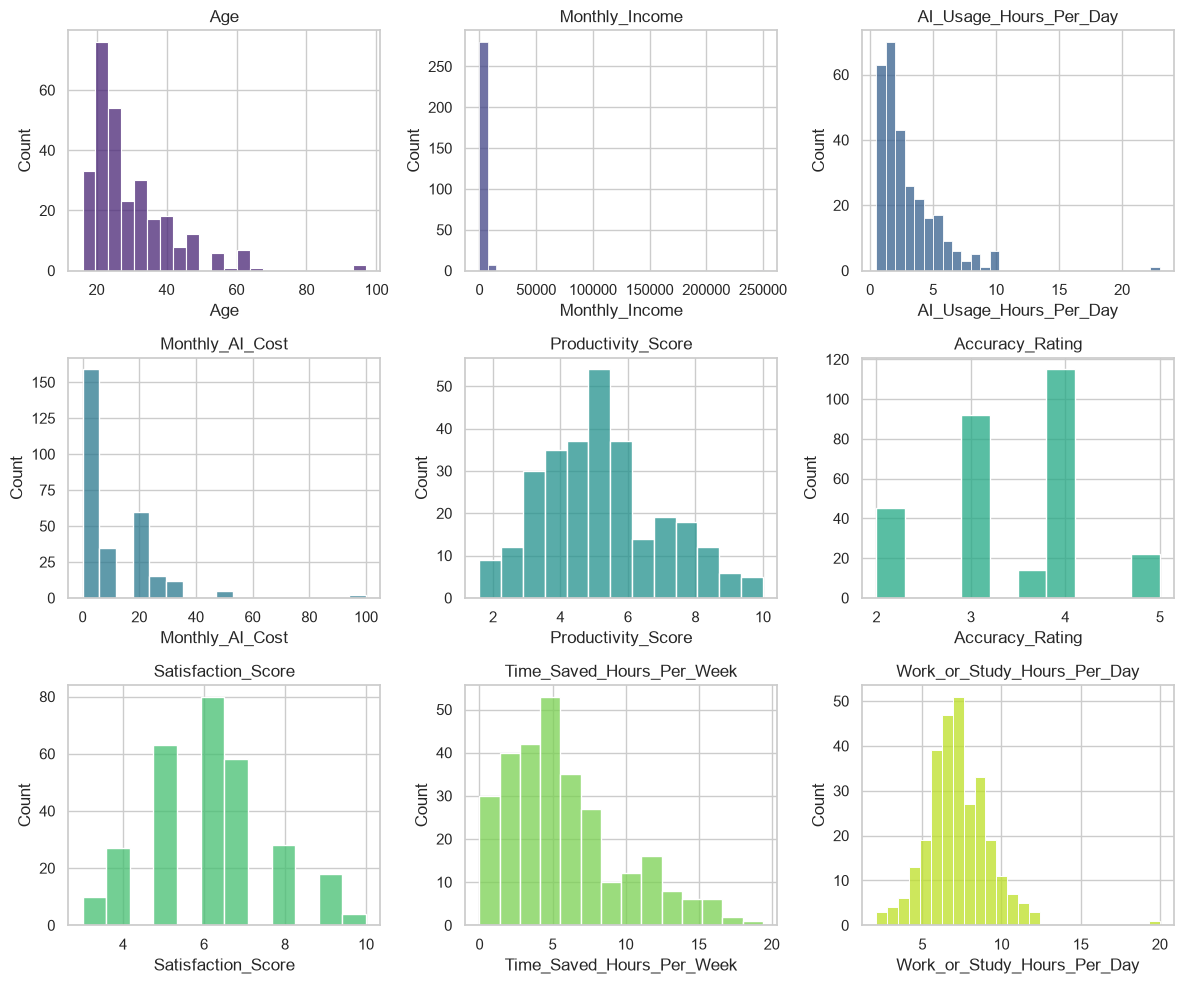

In [6]:
sns.set_theme(style="whitegrid")
palette = sns.color_palette("viridis", n_colors=len(numeric_cols.columns))

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.ravel()

for ax, column, color in zip(axes, numeric_cols.columns, palette):
    sns.histplot(
        data=numeric_cols,
        x=column,
        bins="auto",
        color=color,
        ax=ax,
    )
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

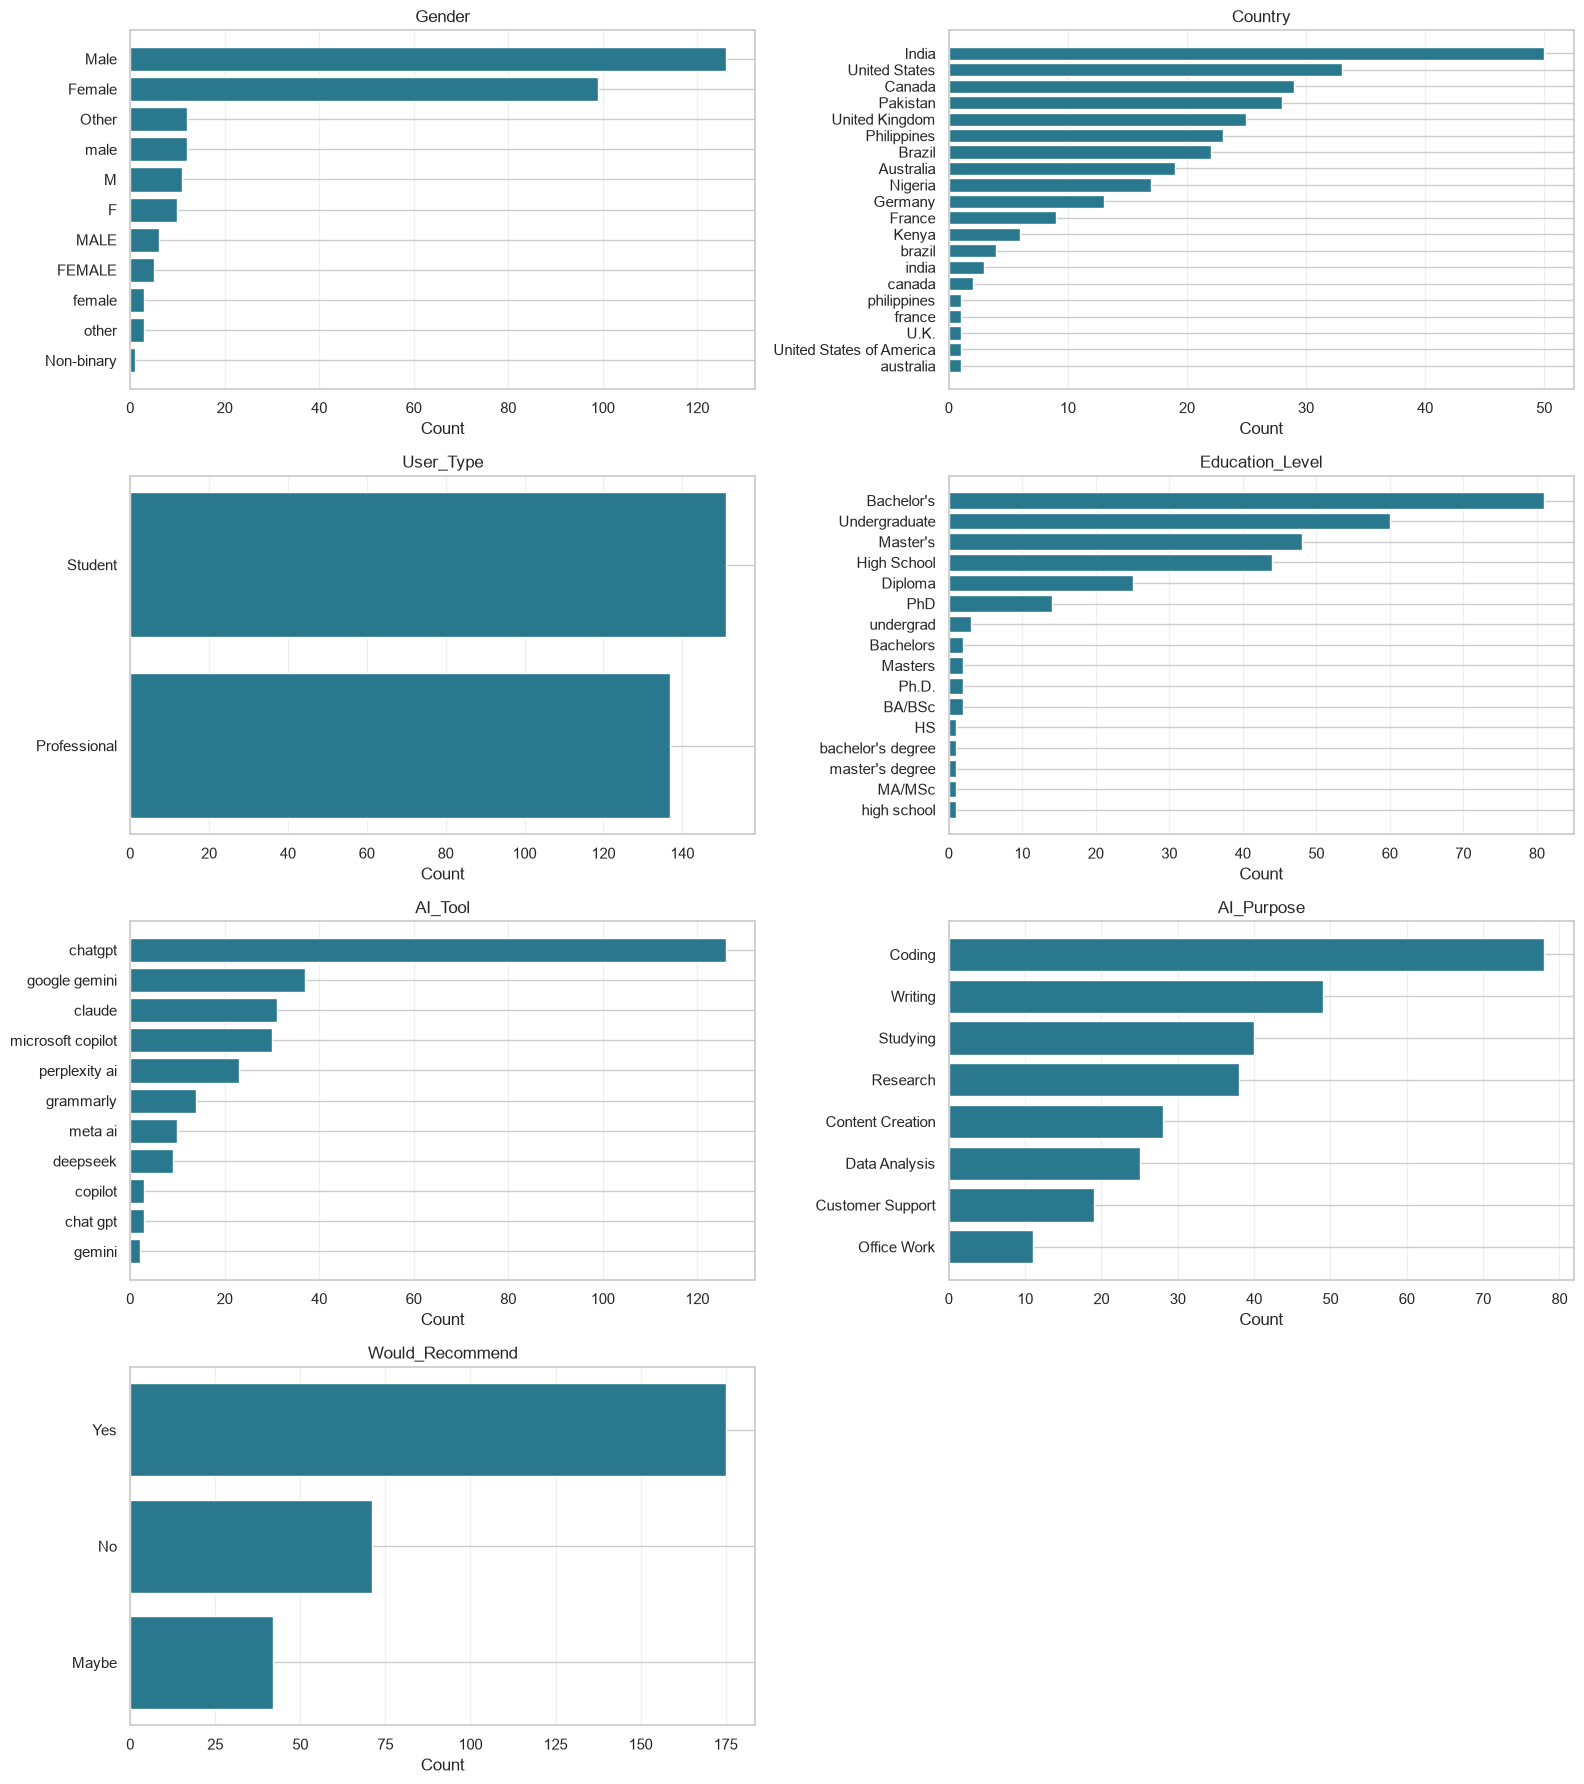

Category
Coding              0.27
Writing             0.17
Studying            0.14
Research            0.13
Content Creation    0.10
Data Analysis       0.09
Customer Support    0.07
Office Work         0.04
Name: Count, dtype: float64

In [9]:
plot_data = pd.concat(
    [
        categories_cols[column]
        .value_counts()
        .rename_axis("Category")
        .reset_index(name="Count")
        .assign(Feature=column)
        for column in categories_cols.columns
        if column not in ["User_ID", "Profession"]
    ],
    ignore_index=True,
)[["Feature", "Category", "Count"]]

features = plot_data["Feature"].unique()
fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.ravel()

for ax, feature in zip(axes, features):
    feature_data = (
        plot_data[plot_data["Feature"] == feature]
        .sort_values("Count", ascending=True)
    )
    ax.barh(feature_data["Category"].astype(str), feature_data["Count"], color=palette[3])
    ax.set_title(feature)
    ax.set_xlabel("Count")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3)

for ax in axes[len(features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

ai_purpose_count = (
    plot_data.loc[plot_data["Feature"] == "AI_Purpose"]
    .set_index("Category")["Count"]
    .div(plot_data.loc[plot_data["Feature"] == "AI_Purpose", "Count"].sum())
)

round(ai_purpose_count,2)

Over 25 percent of respondends use the AI Tools for coding purposes